# Лабораторна робота № 9. Геометричні афінні та перспективні перетворення зображень

### Мета: Засвоїти теоретичні засади та матричний апарат просторових геометричних перетворень цифрових растрових зображень на основі однорідних координат, опанувати алгоритми афінних трансформацій (масштабування, перенесення, обертання та зсуву), дослідити вплив різних методів двовимірної інтерполяції яскравості на якість трансформованого кадру, а також реалізувати алгоритм усунення перспективних спотворень і проективного випрямлення об'єктів на основі матриці гомографії за чотирма опорними точками.

#### *Варіант 2 (№ 22 у списку: $22 - 20 = 2$)*

### <div align="right">Виконав: Яцентюк Євгеній, група: КІ-24-1</div>
<div align="right">
  <a href="https://github.com/kefir4ikk"><b>GitHub</b></a>
</div>

## 1. Імпорт бібліотек та налаштування стилю відображення

In [1]:
import os
import csv
import json
import timeit
import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage

os.makedirs("figures", exist_ok=True)
os.makedirs("data", exist_ok=True)

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#2b2b2b'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['grid.color'] = '#cccccc'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.6

import scipy, matplotlib
print(f"NumPy: {np.__version__} | OpenCV: {cv2.__version__} | Pillow: {Image.__version__} | SciPy: {scipy.__version__} | Matplotlib: {matplotlib.__version__}")

NumPy: 2.5.4 | OpenCV: 5.0.0 | Pillow: 13.0.0 | SciPy: 1.18.1 | Matplotlib: 3.11.2


## 2. Параметри варіанта 2 та постановка завдання

**Індивідуальне завдання (варіант 2):**

| Тип об'єкта | Афінне перетворення $(\theta^\circ,\ s,\ t_x,\ t_y)$ | Координати $src=[P_1,P_2,P_3,P_4]$ | $W_{out}\times H_{out}$, px |
|:-:|:-:|:-:|:-:|
| Текстовий документ на столі | $(-20^\circ,\ 0.90,\ -30,\ 40)$ | `[[180, 80], [620, 130], [710, 510], [70, 470]]` | $500\times350$ |

Координати задано в піксельній системі кадру $800\times600$ (ширина $\times$ висота). Порядок кутів: $P_1$ — лівий верхній, $P_2$ — правий верхній, $P_3$ — правий нижній, $P_4$ — лівий нижній. Кут $\theta>0$ у OpenCV означає поворот проти годинникової стрілки, тому $\theta=-20^\circ$ — поворот за годинниковою стрілкою.

**Афінне перетворення в однорідних координатах.** Для центра $(x_c,y_c)$, $\alpha=s\cos\theta$, $\beta=s\sin\theta$:

$$M=\begin{bmatrix}\alpha&\beta&(1-\alpha)x_c-\beta y_c+t_x\\-\beta&\alpha&\beta x_c+(1-\alpha)y_c+t_y\end{bmatrix}=\underbrace{T(t)\,T(c)\,R(\theta)\,S(s)\,T(-c)}_{\text{добуток матриць }3\times3}\ \text{(перші два рядки)}.$$

Визначник лінійної частини дорівнює $s^2=0.81$ — саме у стільки разів змінюються площі фігур. **Гомографія** $H_{3\times3}$ визначається з точністю до масштабу ($h_{22}=1$), тобто має 8 ступенів вільності, і однозначно знаходиться з чотирьох пар точок (кожна дає два лінійні рівняння відносно $h_{00},\ldots,h_{21}$):

$$\begin{cases}h_{00}x+h_{01}y+h_{02}-h_{20}xx'-h_{21}yx'=x'\\h_{10}x+h_{11}y+h_{12}-h_{20}xy'-h_{21}yy'=y'\end{cases}$$

**Зворотне відображення.** Для кожного цілого пікселя виходу $(x',y')$ обчислюється $(x,y)=T^{-1}(x',y')$ у вхідному кадрі та інтерполюється яскравість. OpenCV отримує матрицю прямого перетворення $src\to dst$ і обертає її всередині, тому `warpAffine` та `warpPerspective` реалізують саме зворотне відображення.

**Тестова сцена.** Для задачі «документ на столі» синтезується документ $500\times350$ (заголовок, рядки тексту, логотип, штрих-код, **шахова ділянка $6\times4$ клітини по 25 px** для вимірювання різкості країв). Він проєктується в кадр $800\times600$ матрицею гомографії за кутами $src$ на тлі «стола» з тінню. Оскільки неспотворений документ відомий, **якість випрямлення вимірюється кількісно** (MSE, PSNR, зсув фазовою кореляцією). Маркери кутів малюються лише на копії для візуалізації, щоб не потрапляти в оброблюваний кадр.

**Що перевіряється в роботі:** матриця $M$ — за замкненою формулою та добутком матриць $3\times3$; афінне перетворення — незалежно через `scipy.ndimage.map_coordinates` та `PIL.Image.transform`; гомографія — власним розв'язанням системи $8\times8$ та ручним зворотним відображенням; властивості (площа, паралельність, точки сходу); частка «дір» при прямому відображенні; порівняння інтерполяцій (MSE, ширина краю 10-90 %, ефект Гіббса, час, накопичення розмиття при поворотах); непридатність афінної моделі для усунення перспективи.

In [2]:
# --- Параметри варіанта 2
H_SCENE, W_SCENE = 600, 800
THETA_DEG, SCALE, TX, TY = -20.0, 0.90, -30.0, 40.0
SRC = np.float32([[180, 80], [620, 130], [710, 510], [70, 470]])
W_OUT, H_OUT = 500, 350
DST = np.float32([[0, 0], [W_OUT - 1, 0], [W_OUT - 1, H_OUT - 1], [0, H_OUT - 1]])      # цільові кути (TL, TR, BR, BL)
CB_X0, CB_Y0, CB_SQ = 326, 225, 25                                                         # шахова ділянка (для вимірювання країв)

def generate_document(h=H_OUT, w=W_OUT, seed=7):
    """Неспотворений документ-еталон 350x500: рамка, заголовок, текст, логотип, штрих-код, шахова ділянка."""
    rng = np.random.default_rng(seed)
    doc = np.full((h, w), 255, np.uint8)
    cv2.rectangle(doc, (12, 12), (w - 13, h - 13), 0, 3)
    cv2.putText(doc, "DOCUMENT 2026", (40, 62), cv2.FONT_HERSHEY_SIMPLEX, 1.0, 0, 2, cv2.LINE_AA)
    cv2.line(doc, (40, 75), (300, 75), 60, 1)
    lines = ["Homography maps a planar scene to the image plane.", "Eight degrees of freedom need four point pairs.",
             "Inverse mapping avoids holes in the output grid.", "Interpolation controls blur and ringing of edges.",
             "Affine maps keep parallel lines parallel.", "Perspective maps send parallels to vanishing points."]
    for i, t in enumerate(lines):
        cv2.putText(doc, t, (40, 100 + 20 * i), cv2.FONT_HERSHEY_SIMPLEX, 0.42, 20, 1, cv2.LINE_AA)
    cv2.circle(doc, (415, 55), 30, 80, -1); cv2.circle(doc, (415, 55), 16, 200, -1)
    x = 40
    while x < 220:                                                                         # штрих-код
        bw = int(rng.integers(1, 5)); cv2.rectangle(doc, (x, 250), (x + bw - 1, 315), 0, -1); x += bw + int(rng.integers(1, 4))
    for r in range(4):                                                                     # шахова ділянка 6x4 клітини
        for c in range(6):
            if (r + c) % 2 == 0:
                cv2.rectangle(doc, (CB_X0 + c * CB_SQ, CB_Y0 + r * CB_SQ), (CB_X0 + (c + 1) * CB_SQ - 1, CB_Y0 + (r + 1) * CB_SQ - 1), 0, -1)
    return doc

def generate_scene(doc, seed=3):
    """Кадр 800x600: документ у перспективі (за кутами SRC) на текстурованому столі з тінню."""
    yy, xx = np.mgrid[0:H_SCENE, 0:W_SCENE].astype(np.float32)
    table = np.clip(140 + 18 * np.sin(yy / 5.0 + 0.8 * np.sin(xx / 60.0)) + 25 * xx / W_SCENE, 0, 255)
    H_proj = cv2.getPerspectiveTransform(DST, SRC)                                         # площина документа -> кадр
    quad = np.zeros((H_SCENE, W_SCENE), np.uint8); cv2.fillConvexPoly(quad, np.round(SRC).astype(np.int32), 255)
    shadow = cv2.GaussianBlur(np.roll(np.roll(quad, 14, axis=0), 10, axis=1), (0, 0), 9) / 255.0
    table = table * (1 - 0.35 * shadow)
    doc_w = cv2.warpPerspective(doc, H_proj, (W_SCENE, H_SCENE), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE).astype(np.float32)
    alpha = cv2.warpPerspective(np.full(doc.shape, 255, np.uint8), H_proj, (W_SCENE, H_SCENE), flags=cv2.INTER_LINEAR, borderValue=0).astype(np.float32) / 255.0
    return np.clip(np.rint(alpha * doc_w + (1 - alpha) * table), 0, 255).astype(np.uint8), H_proj

def order_points(pts):
    """Упорядкування кутів: TL (min x+y), TR (min y-x), BR (max x+y), BL (max y-x)."""
    pts = np.asarray(pts, np.float32); s_ = pts.sum(1); d_ = np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s_)], pts[np.argmin(d_)], pts[np.argmax(s_)], pts[np.argmax(d_)]])

doc_gt = generate_document()
scene_clean, H_proj = generate_scene(doc_gt)
scene_marked = scene_clean.copy()
for pt in SRC.astype(int):
    cv2.circle(scene_marked, tuple(int(v) for v in pt), 7, 30, -1); cv2.circle(scene_marked, tuple(int(v) for v in pt), 4, 255, -1)
cv2.imwrite("data/document_ground_truth.png", doc_gt)
cv2.imwrite("data/perspective_scene_clean.png", scene_clean)
cv2.imwrite("data/perspective_scene.png", scene_marked)
assert np.array_equal(order_points(np.random.default_rng(0).permutation(SRC)), SRC)         # порядок кутів у варіанті TL, TR, BR, BL
print(f"Сцена {W_SCENE}x{H_SCENE} (діапазон яскравості [{scene_clean.min()}, {scene_clean.max()}]) та еталонний документ {W_OUT}x{H_OUT} збережено в data/")

Сцена 800x600 (діапазон яскравості [0, 255]) та еталонний документ 500x350 збережено в data/


## 3. Комплексне афінне перетворення (`warpAffine`)

Матриця $M_{2\times3}$ будується `cv2.getRotationMatrix2D` із додаванням зсуву $(t_x,t_y)$. Вона звіряється з замкненою формулою та з добутком матриць $3\times3$ в однорідних координатах. Результат `warpAffine` (білінійна інтерполяція) звіряється з двома незалежними реалізаціями зворотного відображення: `scipy.ndimage.map_coordinates` (порядок 1) та `PIL.Image.transform`. Додатково перевіряються площа ($\times s^2$), паралельність та відношення довжин, а також частка пікселів-«дір» при **прямому** відображенні.

МАТРИЦЯ АФІННОГО ПЕРЕТВОРЕННЯ (2x3)
Кут θ = -20.0° | масштаб s = 0.9 | зсув (-30.0, 40.0) px | центр (400.0, 300.0)
α = s·cosθ = 0.845723; β = s·sinθ = -0.307818; det(лінійної частини) = 0.8100 (s² = 0.8100)
M_affine =
[[  0.845723  -0.307818 124.056095]
 [  0.307818   0.845723 -36.844259]]
Матриця 3x3 (однорідні координати) T(t)·T(c)·R·S·T(-c) збігається з M: True
----------------------------------------------------------------------------------
Верифікація warpAffine (INTER_LINEAR) в області валідності (74.4 % кадру):
  scipy.ndimage.map_coordinates (order=1): max|Δ| = 0.504, середнє = 0.147
  PIL.Image.transform (BILINEAR):           max|Δ| = 1.000, середнє = 0.296
Площа чотирикутника src після M: ×0.8100 (очікується s² = 0.8100); паралельність відрізків зберігається (|sin| = 9.7e-17); відношення 1:3 зберігається (0.2500)
Пряме відображення (округлення координат): частка пікселів-«дір» у області валідності = 2.91 % (зворотне відображення: 0 % за побудовою)
Образи кутів src після M: 

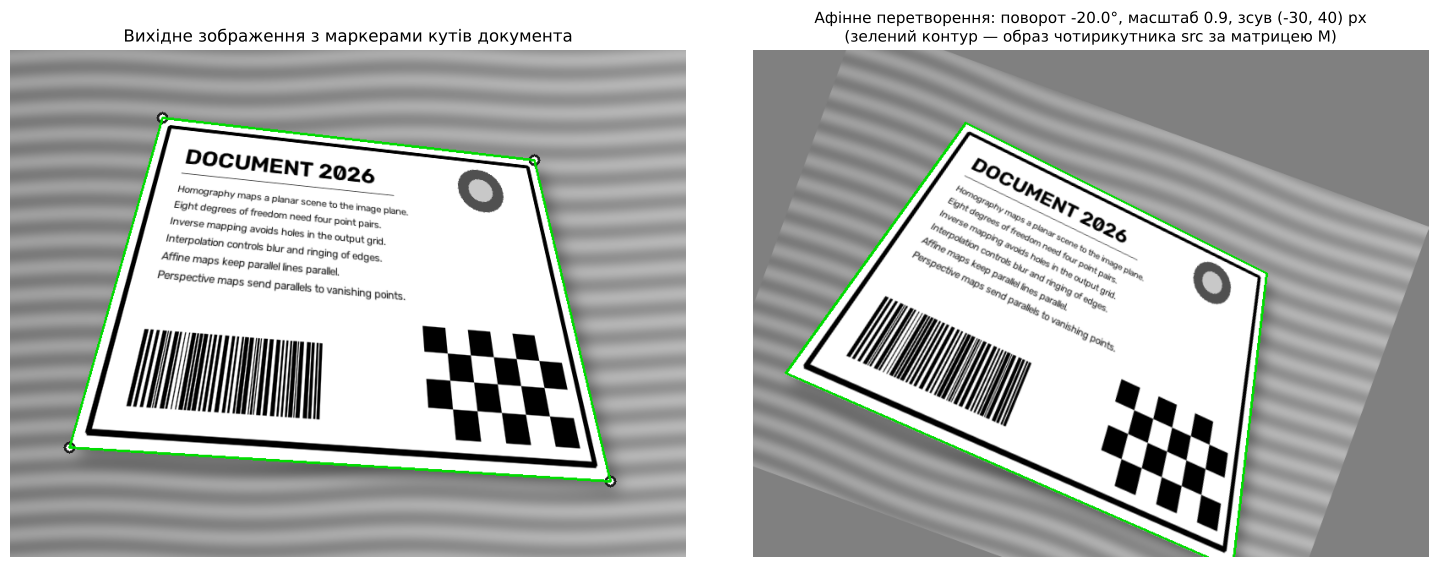

True

In [3]:
center = (W_SCENE / 2.0, H_SCENE / 2.0)
M = cv2.getRotationMatrix2D(center=center, angle=THETA_DEG, scale=SCALE)
M[0, 2] += TX; M[1, 2] += TY

# --- 1) Замкнена формула та добуток матриць 3x3
th = np.deg2rad(THETA_DEG); alpha, beta = SCALE * np.cos(th), SCALE * np.sin(th)
M_closed = np.array([[alpha, beta, (1 - alpha) * center[0] - beta * center[1] + TX],
                     [-beta, alpha, beta * center[0] + (1 - alpha) * center[1] + TY]])
Tm = lambda a, b: np.array([[1, 0, a], [0, 1, b], [0, 0, 1.0]])
R3 = np.array([[np.cos(th), np.sin(th), 0], [-np.sin(th), np.cos(th), 0], [0, 0, 1.0]]); S3 = np.diag([SCALE, SCALE, 1.0])
M3 = Tm(TX, TY) @ Tm(*center) @ R3 @ S3 @ Tm(-center[0], -center[1])
assert np.allclose(M, M_closed) and np.allclose(M3[:2], M) and np.allclose(M3[2], [0, 0, 1])

img_aff = cv2.warpAffine(scene_clean, M, (W_SCENE, H_SCENE), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_CONSTANT, borderValue=128)

# --- 2) Незалежні реалізації зворотного відображення
Mi = cv2.invertAffineTransform(M)
yy, xx = np.mgrid[0:H_SCENE, 0:W_SCENE].astype(np.float64)
xs, ys = Mi[0, 0] * xx + Mi[0, 1] * yy + Mi[0, 2], Mi[1, 0] * xx + Mi[1, 1] * yy + Mi[1, 2]
valid = (xs >= 0) & (xs <= W_SCENE - 1) & (ys >= 0) & (ys <= H_SCENE - 1)
valid_in = cv2.erode(valid.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0
img_scipy = ndimage.map_coordinates(scene_clean.astype(np.float64), [ys, xs], order=1, mode='constant', cval=128)
a_, b_, c_ = Mi[0]; d_, e_, f_ = Mi[1]                                                  # PIL: центри пікселів зміщені на 0.5
img_pil = np.asarray(Image.fromarray(scene_clean).transform((W_SCENE, H_SCENE), Image.AFFINE, (a_, b_, c_ + 0.5 - 0.5 * a_ - 0.5 * b_, d_, e_, f_ + 0.5 - 0.5 * d_ - 0.5 * e_),
                                                             resample=Image.BILINEAR, fillcolor=128))
d_sp = np.abs(img_scipy - img_aff.astype(float))[valid_in]; d_pil = np.abs(img_pil.astype(float) - img_aff.astype(float))[valid_in]

# --- 3) Геометричні властивості афінного відображення
def shoelace(p): return 0.5 * abs(np.dot(p[:, 0], np.roll(p[:, 1], -1)) - np.dot(p[:, 1], np.roll(p[:, 0], -1)))
quad_aff = cv2.transform(SRC.reshape(-1, 1, 2), M).reshape(-1, 2)
area_ratio = shoelace(quad_aff.astype(np.float64)) / shoelace(SRC.astype(np.float64))
pa, pb, pc, pd = (np.array(v, float) for v in ([0, 0], [100, 40], [0, 70], [100, 110]))           # два паралельні відрізки pa->pb, pc->pd
tr = lambda p: M[:, :2] @ p + M[:, 2]
u1, u2 = tr(pb) - tr(pa), tr(pd) - tr(pc)
cross_par = abs(u1[0] * u2[1] - u1[1] * u2[0]) / (np.linalg.norm(u1) * np.linalg.norm(u2))
pm = pa + 0.25 * (pb - pa); ratio_pres = np.linalg.norm(tr(pm) - tr(pa)) / np.linalg.norm(tr(pb) - tr(pa))

# --- 4) Пряме відображення: частка «дір»
Ys, Xs = np.mgrid[0:H_SCENE, 0:W_SCENE]
dx = np.rint(M[0, 0] * Xs + M[0, 1] * Ys + M[0, 2]).astype(int); dy = np.rint(M[1, 0] * Xs + M[1, 1] * Ys + M[1, 2]).astype(int)
inb = (dx >= 0) & (dx < W_SCENE) & (dy >= 0) & (dy < H_SCENE)
hit = np.zeros((H_SCENE, W_SCENE), bool); hit[dy[inb], dx[inb]] = True
holes_pct = 100 * float(np.mean(~hit[valid_in]))

print("=" * 82)
print("МАТРИЦЯ АФІННОГО ПЕРЕТВОРЕННЯ (2x3)")
print("=" * 82)
print(f"Кут θ = {THETA_DEG}° | масштаб s = {SCALE} | зсув ({TX}, {TY}) px | центр {center}")
print(f"α = s·cosθ = {alpha:.6f}; β = s·sinθ = {beta:.6f}; det(лінійної частини) = {np.linalg.det(M[:, :2]):.4f} (s² = {SCALE ** 2:.4f})")
print("M_affine =\n" + np.array2string(M, precision=6, suppress_small=True))
print("Матриця 3x3 (однорідні координати) T(t)·T(c)·R·S·T(-c) збігається з M: True")
print("-" * 82)
print(f"Верифікація warpAffine (INTER_LINEAR) в області валідності ({100 * valid_in.mean():.1f} % кадру):")
print(f"  scipy.ndimage.map_coordinates (order=1): max|Δ| = {d_sp.max():.3f}, середнє = {d_sp.mean():.3f}")
print(f"  PIL.Image.transform (BILINEAR):           max|Δ| = {d_pil.max():.3f}, середнє = {d_pil.mean():.3f}")
print(f"Площа чотирикутника src після M: ×{area_ratio:.4f} (очікується s² = {SCALE ** 2:.4f}); паралельність відрізків зберігається (|sin| = {cross_par:.1e}); "
      f"відношення 1:3 зберігається ({ratio_pres:.4f})")
print(f"Пряме відображення (округлення координат): частка пікселів-«дір» у області валідності = {holes_pct:.2f} % (зворотне відображення: 0 % за побудовою)")
print("Образи кутів src після M:", np.round(quad_aff, 1).tolist())
print("=" * 82)
assert d_sp.max() <= 1.0 and d_pil.max() <= 1.5 and abs(area_ratio - SCALE ** 2) < 1e-9

# --- Візуалізація
left = cv2.cvtColor(scene_marked, cv2.COLOR_GRAY2BGR); cv2.polylines(left, [np.round(SRC).astype(np.int32).reshape(-1, 1, 2)], True, (0, 220, 0), 2)
right = cv2.cvtColor(img_aff, cv2.COLOR_GRAY2BGR); cv2.polylines(right, [np.round(quad_aff).astype(np.int32).reshape(-1, 1, 2)], True, (0, 220, 0), 2)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
axes[0].imshow(cv2.cvtColor(left, cv2.COLOR_BGR2RGB)); axes[0].set_title("Вихідне зображення з маркерами кутів документа")
axes[1].imshow(cv2.cvtColor(right, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"Афінне перетворення: поворот {THETA_DEG}°, масштаб {SCALE}, зсув ({TX:.0f}, {TY:.0f}) px\n(зелений контур — образ чотирикутника src за матрицею M)", fontsize=11)
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/affine_transform_results.png", dpi=200)
plt.show()
cv2.imwrite("data/affine_result.png", img_aff)

## 4. Порівняння методів інтерполяції при двократному масштабуванні

Протокол із відомим еталоном: документ $500\times350$ зменшується вдвічі (`INTER_AREA`) до $250\times175$, а потім збільшується вдвічі кожним із чотирьох методів. Результат порівнюється з оригіналом: $\mathrm{MSE}$, $\mathrm{PSNR}$, ширина краю на шаховій ділянці (за рівнями $10$-$90\,\%$ профілю), амплітуда перерегулювання (ефект Гіббса, визначається на `float32` без відсікання). Для оцінки накопичення розмиття виконуються послідовні повороти на $+\theta$ та $-\theta$, а вартість кожного методу вимірюється часом `resize` великого кадру.

ПОРІВНЯЛЬНИЙ АНАЛІЗ МЕТОДІВ ІНТЕРПОЛЯЦІЇ (збільшення у 2 рази зменшеного еталона)
Метод             опорних      MSE  PSNR, дБ  PSNR шахова, дБ  ширина краю 10-90 %, px  перерегулювання    PSNR після 1 / 4 циклів повороту   час 2000²→4000², мс
INTER_NEAREST           1   1274.3     17.08            17.63                     2.60             0.00               23.18 / 23.11                      5.4
INTER_LINEAR            4   1329.3     16.89            18.06                     3.41             0.00               21.79 / 17.20                      5.4
INTER_CUBIC            16   1142.1     17.55            19.16                     2.97            66.54               25.96 / 22.45                      8.1
INTER_LANCZOS4         64   1132.4     17.59            19.25                     2.81            97.52               27.35 / 24.69                     65.2
Ширина краю еталона (10-90 %): 0.80 px


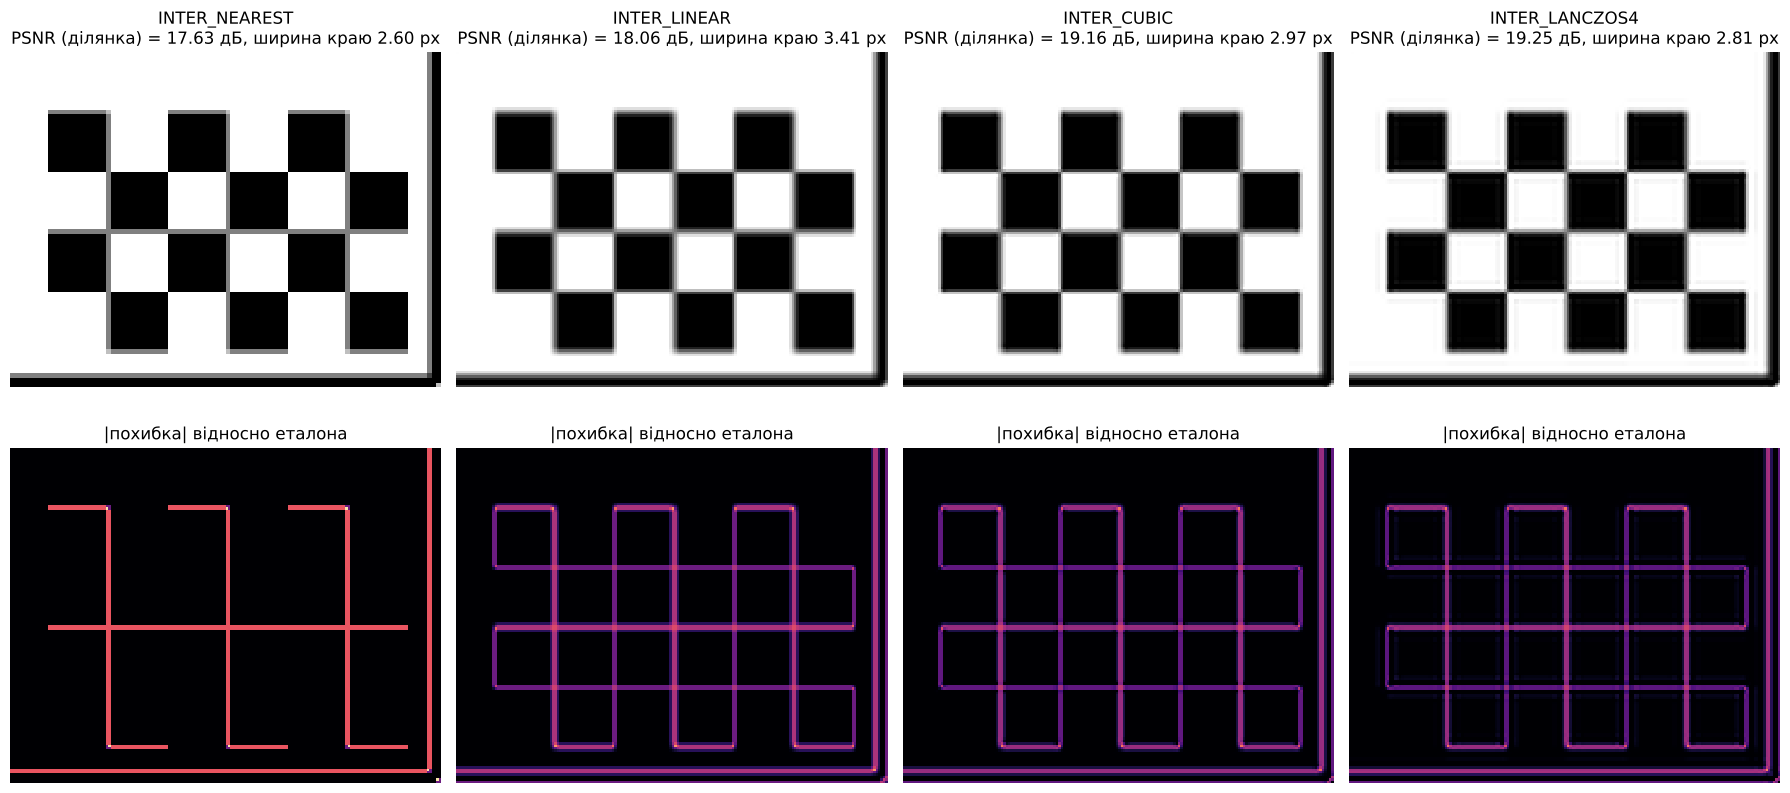

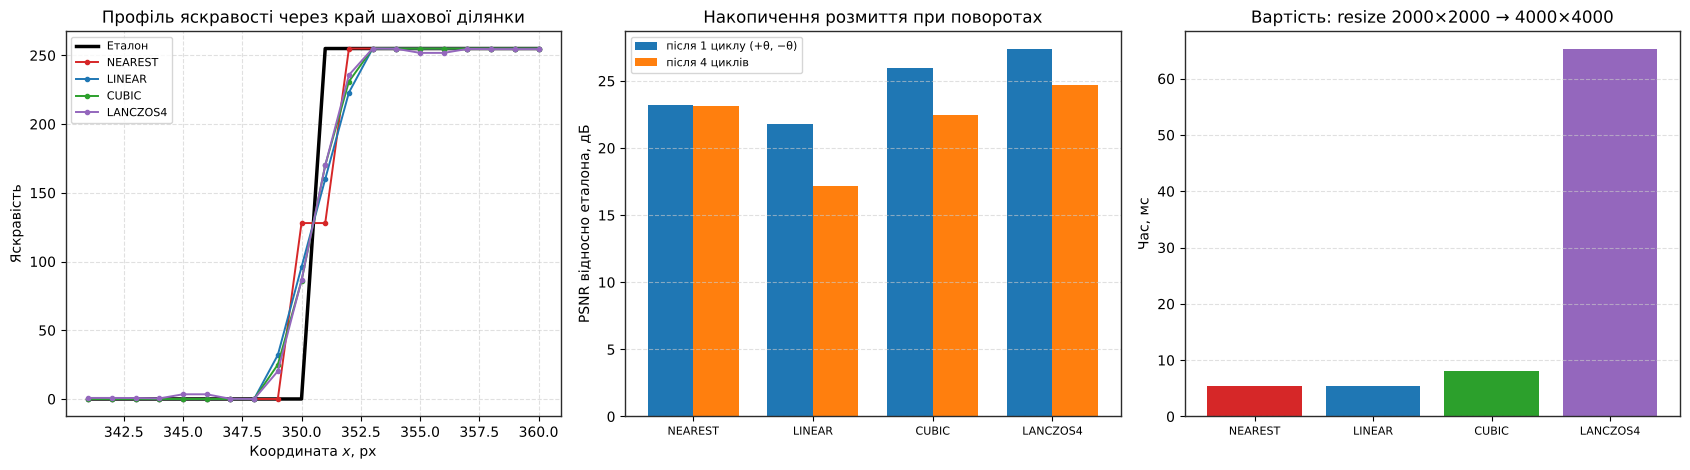

In [4]:
INTERP = {'INTER_NEAREST': cv2.INTER_NEAREST, 'INTER_LINEAR': cv2.INTER_LINEAR, 'INTER_CUBIC': cv2.INTER_CUBIC, 'INTER_LANCZOS4': cv2.INTER_LANCZOS4}
SUPPORT = {'INTER_NEAREST': 1, 'INTER_LINEAR': 4, 'INTER_CUBIC': 16, 'INTER_LANCZOS4': 64}
x_edge = CB_X0 + CB_SQ                                           # вертикальний край шахової ділянки в еталоні
rows_edge = (CB_Y0 + 4, CB_Y0 + CB_SQ - 4)

def psnr_mse(ref, proc, region=None):
    a, b = ref.astype(np.float64), proc.astype(np.float64)
    if region is not None: a, b = a[region], b[region]
    mse = float(np.mean((a - b) ** 2)); return mse, (float('inf') if mse == 0 else 10 * np.log10(255.0 ** 2 / mse))

def edge_profile(img):
    return img[rows_edge[0]:rows_edge[1], x_edge - 10:x_edge + 10].astype(np.float64).mean(0)

def edge_width_10_90(img):
    p = edge_profile(img); lo, hi = p[:4].mean(), p[-4:].mean(); p = (p - lo) / (hi - lo); xs_ = np.arange(x_edge - 10, x_edge + 10)
    def cross(level):
        i = np.where((p[:-1] < level) & (p[1:] >= level))[0][0]; return xs_[i] + (level - p[i]) / (p[i + 1] - p[i])
    return float(cross(0.9) - cross(0.1))

cb_region = np.zeros((H_OUT, W_OUT), bool); cb_region[CB_Y0:CB_Y0 + 4 * CB_SQ, CB_X0:CB_X0 + 6 * CB_SQ] = True            # шахова ділянка: переважно краї
low_u8 = cv2.resize(doc_gt, (W_OUT // 2, H_OUT // 2), interpolation=cv2.INTER_AREA)
low_f32 = cv2.resize(doc_gt.astype(np.float32), (W_OUT // 2, H_OUT // 2), interpolation=cv2.INTER_AREA)
ups, interp_rows = {}, []
for nm, flag in INTERP.items():
    up = cv2.resize(low_u8, (W_OUT, H_OUT), interpolation=flag); ups[nm] = up
    upf = cv2.resize(low_f32, (W_OUT, H_OUT), interpolation=flag)
    mse_, psnr_ = psnr_mse(doc_gt, up)
    interp_rows.append(dict(method=nm, support=SUPPORT[nm], mse=mse_, psnr=psnr_, psnr_checker=psnr_mse(doc_gt, up, cb_region)[1], edge_width=edge_width_10_90(up),
                            overshoot=float(max(upf.max() - 255, -upf.min(), 0))))

# Накопичення розмиття при поворотах +theta / -theta (центральна область без втрати кутів)
cen = (W_OUT / 2, H_OUT / 2)
Rf, Rb = cv2.getRotationMatrix2D(cen, THETA_DEG, 1.0), cv2.getRotationMatrix2D(cen, -THETA_DEG, 1.0)
yy_, xx_ = np.mgrid[0:H_OUT, 0:W_OUT]; inner = (xx_ - cen[0]) ** 2 + (yy_ - cen[1]) ** 2 < 140 ** 2
rot_psnr = {}
for nm, flag in INTERP.items():
    cur, out_p = doc_gt.copy(), []
    for trip in range(1, 5):
        cur = cv2.warpAffine(cv2.warpAffine(cur, Rf, (W_OUT, H_OUT), flags=flag, borderValue=255), Rb, (W_OUT, H_OUT), flags=flag, borderValue=255)
        if trip in (1, 4): out_p.append(psnr_mse(doc_gt, cur, inner)[1])
    rot_psnr[nm] = out_p

# Час: resize кадру 2000x2000 -> 4000x4000 (мінімум із 3 серій)
big = cv2.resize(scene_clean, (2000, 2000), interpolation=cv2.INTER_LINEAR)
time_ms = {nm: min(timeit.repeat(lambda: cv2.resize(big, (4000, 4000), interpolation=fl), number=1, repeat=3)) * 1e3 for nm, fl in INTERP.items()}

print("=" * 125)
print("ПОРІВНЯЛЬНИЙ АНАЛІЗ МЕТОДІВ ІНТЕРПОЛЯЦІЇ (збільшення у 2 рази зменшеного еталона)")
print("=" * 125)
print(f"{'Метод':<16}{'опорних':>9}{'MSE':>9}{'PSNR, дБ':>10}{'PSNR шахова, дБ':>17}{'ширина краю 10-90 %, px':>25}{'перерегулювання':>17}{'PSNR після 1 / 4 циклів повороту':>36}{'час 2000²→4000², мс':>22}")
for r_ in interp_rows:
    nm = r_['method']
    print(f"{nm:<16}{r_['support']:9d}{r_['mse']:9.1f}{r_['psnr']:10.2f}{r_['psnr_checker']:17.2f}{r_['edge_width']:25.2f}{r_['overshoot']:17.2f}{rot_psnr[nm][0]:>20.2f} / {rot_psnr[nm][1]:<8.2f}{time_ms[nm]:22.1f}")
print("=" * 125)
print(f"Ширина краю еталона (10-90 %): {edge_width_10_90(doc_gt):.2f} px")

# --- Візуалізація: фрагмент (шахова ділянка) та карти похибки
r0, r1, c0, c1 = 200, 340, 310, 490
fig, axes = plt.subplots(2, 4, figsize=(18, 8.6))
for j, r_ in enumerate(interp_rows):
    nm = r_['method']
    axes[0, j].imshow(ups[nm][r0:r1, c0:c1], cmap='gray', vmin=0, vmax=255, interpolation='nearest')
    axes[0, j].set_title(f"{nm}\nPSNR (ділянка) = {r_['psnr_checker']:.2f} дБ, ширина краю {r_['edge_width']:.2f} px")
    axes[1, j].imshow(np.abs(ups[nm][r0:r1, c0:c1].astype(float) - doc_gt[r0:r1, c0:c1]), cmap='magma', vmin=0, vmax=200, interpolation='nearest')
    axes[1, j].set_title("|похибка| відносно еталона")
for ax in axes.flat:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/interpolation_comparison.png", dpi=200)
plt.show()

# --- Профілі країв, накопичення розмиття, час
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
xs_p = np.arange(x_edge - 10, x_edge + 10)
axes[0].plot(xs_p, edge_profile(doc_gt), 'k-', lw=2.5, label='Еталон')
for (nm, up), col in zip(ups.items(), ['#d62728', '#1f77b4', '#2ca02c', '#9467bd']):
    axes[0].plot(xs_p, edge_profile(up), '-o', ms=3, color=col, lw=1.4, label=nm.replace('INTER_', ''))
axes[0].set_title("Профіль яскравості через край шахової ділянки"); axes[0].set_xlabel("Координата $x$, px"); axes[0].set_ylabel("Яскравість"); axes[0].grid(True); axes[0].legend(fontsize=8)
bw = 0.38; names_s = [n.replace('INTER_', '') for n in INTERP]
axes[1].bar(np.arange(4) - bw / 2, [rot_psnr[n][0] for n in INTERP], bw, label='після 1 циклу (+θ, −θ)', color='#1f77b4')
axes[1].bar(np.arange(4) + bw / 2, [rot_psnr[n][1] for n in INTERP], bw, label='після 4 циклів', color='#ff7f0e')
axes[1].set_xticks(np.arange(4)); axes[1].set_xticklabels(names_s, fontsize=8); axes[1].set_ylabel("PSNR відносно еталона, дБ"); axes[1].set_title("Накопичення розмиття при поворотах"); axes[1].grid(True, axis='y'); axes[1].legend(fontsize=8)
axes[2].bar(names_s, [time_ms[n] for n in INTERP], color=['#d62728', '#1f77b4', '#2ca02c', '#9467bd'])
axes[2].set_ylabel("Час, мс"); axes[2].set_title("Вартість: resize 2000×2000 → 4000×4000"); axes[2].grid(True, axis='y'); axes[2].tick_params(axis='x', labelsize=8)
plt.tight_layout()
plt.savefig("figures/interpolation_quality.png", dpi=200)
plt.show()

## 5. Перспективне випрямлення документа за матрицею гомографії

Матриця $H_{3\times3}$ знаходиться `cv2.getPerspectiveTransform` за чотирма парами точок $src\to dst$ і звіряється з власним розв'язанням лінійної системи $8\times8$ (DLT). Перевіряються: похибка відображення опорних точок, добуток із матрицею прямої проєкції ($H\cdot H_{proj}\approx I$), визначник та число обумовленості, **точки сходу** (перетин ліній, що в документі паралельні; їх образ при $H$ має $w=0$), кути між краями документа у кадрі. Власна реалізація зворотного відображення (`map_coordinates`) звіряється з `warpPerspective`. Якість випрямлення порівнюється для чотирьох інтерполяцій з еталонним документом (без смуги $3$ px по краях, де документ змішується з тлом), а також з **афінною** спробою за трьома точками та за методом найменших квадратів по чотирьох точках.

МАТРИЦЯ ПЕРСПЕКТИВНОГО ПЕРЕТВОРЕННЯ ГОМОГРАФІЇ H (3x3), src -> dst
H_matrix =
[[ 1.085000e+00  3.060257e-01 -2.197821e+02]
 [-1.518820e-01  1.336562e+00 -7.958617e+01]
 [-2.703543e-04  1.192287e-03  1.000000e+00]]
det(H) = 1.5666e+00; число обумовленості cond(H) = 4.3990e+04
Власне розв'язання системи 8x8: max|H_DLT - H_cv2| = 2.84e-14
Похибка відображення опорних точок src -> dst: max = 1.14e-13 px
H·H_proj ≈ I (до масштабу): max|H·H_proj - I| = 4.07e-14
Ручне зворотне відображення проти warpPerspective(INTER_LINEAR): max|Δ| = 0.508, середнє = 0.0575
----------------------------------------------------------------------------------------
Кути сторін документа у кадрі: верх 6.48°, низ 3.58° (різниця 2.91°); ліво 105.75°, право 76.68° (різниця -29.08°)
Точки сходу: по горизонталі (7941, 962), по вертикалі (413, -745); відносне w = (H·v)_3 -> 1.7e-19, 4.4e-19 (≈ 0: точки на нескінченності)

Випрямлення (warpPerspective)         MSE  PSNR, дБ   зсув (фаз. кореляція), px   ширина краю, px


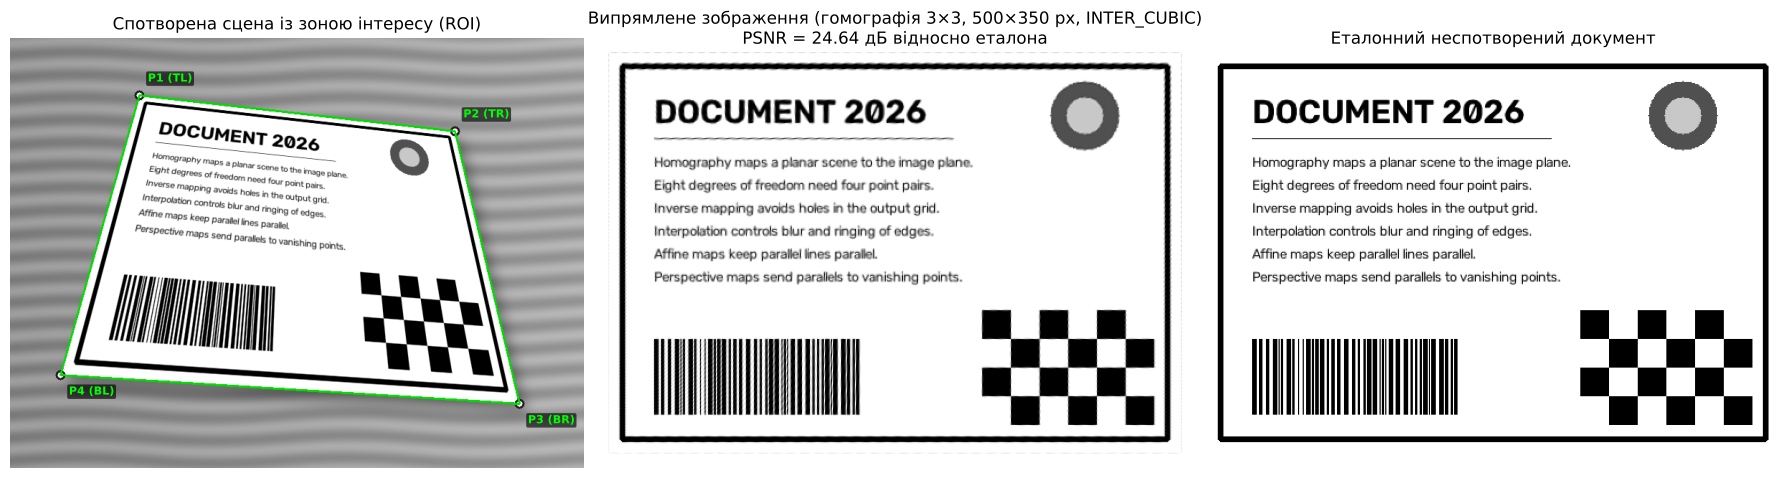

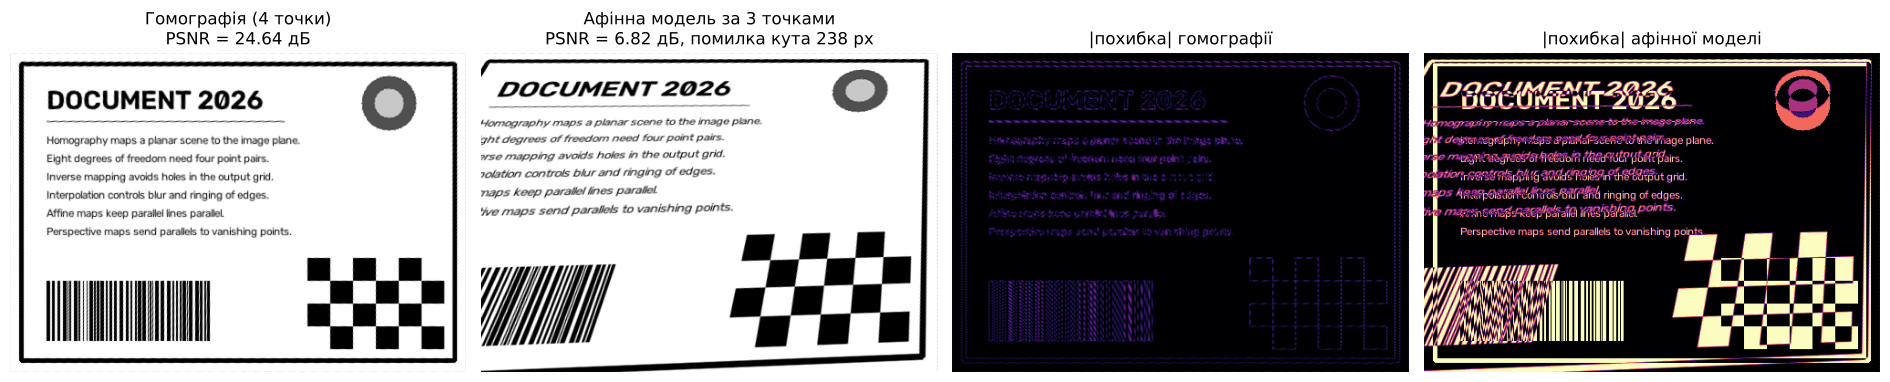

In [5]:
src_pts = order_points(SRC)
H_rect = cv2.getPerspectiveTransform(src_pts, DST)

# --- 1) Власне розв'язання системи 8x8 (DLT, h22 = 1)
def homography_dlt(src, dst):
    A, b = [], []
    for (x, y), (xp, yp) in zip(src.astype(np.float64), dst.astype(np.float64)):
        A.append([x, y, 1, 0, 0, 0, -x * xp, -y * xp]); b.append(xp)
        A.append([0, 0, 0, x, y, 1, -x * yp, -y * yp]); b.append(yp)
    h = np.linalg.solve(np.array(A), np.array(b))
    return np.append(h, 1.0).reshape(3, 3)
H_dlt = homography_dlt(src_pts, DST)

apply_h = lambda Hm, p: (lambda q: q[:, :2] / q[:, 2:3])((np.c_[p, np.ones(len(p))] @ Hm.T))
reproj_err = np.abs(apply_h(H_rect, src_pts.astype(np.float64)) - DST).max()
Hp_n = H_proj / H_proj[2, 2]; prod = H_rect @ Hp_n; prod /= prod[2, 2]
det_H = float(np.linalg.det(H_rect)); cond_H = float(np.linalg.cond(H_rect))

# --- 2) Точки сходу: образи паралельних (у документі) сторін у кадрі
line = lambda p, q: np.cross(np.r_[p, 1.0], np.r_[q, 1.0])
P1, P2, P3, P4 = (src_pts[i].astype(np.float64) for i in range(4))
vp_h = np.cross(line(P1, P2), line(P4, P3)); vp_v = np.cross(line(P1, P4), line(P2, P3))        # верхня/нижня та ліва/права сторони
w_vp = [abs((H_rect @ v)[2]) / np.linalg.norm(H_rect[2]) / np.linalg.norm(v) for v in (vp_h, vp_v)]
vp_h_xy, vp_v_xy = vp_h[:2] / vp_h[2], vp_v[:2] / vp_v[2]
ang = lambda p, q: np.degrees(np.arctan2(q[1] - p[1], q[0] - p[0]))
ang_top, ang_bot, ang_left, ang_right = ang(P1, P2), ang(P4, P3), ang(P1, P4), ang(P2, P3)

# --- 3) Ручне зворотне відображення (map_coordinates) проти warpPerspective
Hi = np.linalg.inv(H_rect)
yo, xo = np.mgrid[0:H_OUT, 0:W_OUT].astype(np.float64)
q = Hi @ np.stack([xo.ravel(), yo.ravel(), np.ones(xo.size)]); xs_s, ys_s = (q[0] / q[2]).reshape(H_OUT, W_OUT), (q[1] / q[2]).reshape(H_OUT, W_OUT)
rect_manual = ndimage.map_coordinates(scene_clean.astype(np.float64), [ys_s, xs_s], order=1, mode='nearest')
rect_lin = cv2.warpPerspective(scene_clean, H_rect, (W_OUT, H_OUT), flags=cv2.INTER_LINEAR)
d_man = np.abs(rect_manual - rect_lin.astype(float))

print("=" * 88)
print("МАТРИЦЯ ПЕРСПЕКТИВНОГО ПЕРЕТВОРЕННЯ ГОМОГРАФІЇ H (3x3), src -> dst")
print("=" * 88)
print("H_matrix =\n" + np.array2string(H_rect, precision=6, suppress_small=False))
print(f"det(H) = {det_H:.4e}; число обумовленості cond(H) = {cond_H:.4e}")
print(f"Власне розв'язання системи 8x8: max|H_DLT - H_cv2| = {np.abs(H_dlt - H_rect).max():.2e}")
print(f"Похибка відображення опорних точок src -> dst: max = {reproj_err:.2e} px")
print(f"H·H_proj ≈ I (до масштабу): max|H·H_proj - I| = {np.abs(prod - np.eye(3)).max():.2e}")
print(f"Ручне зворотне відображення проти warpPerspective(INTER_LINEAR): max|Δ| = {d_man.max():.3f}, середнє = {d_man.mean():.4f}")
print("-" * 88)
print(f"Кути сторін документа у кадрі: верх {ang_top:.2f}°, низ {ang_bot:.2f}° (різниця {ang_top - ang_bot:.2f}°); ліво {ang_left:.2f}°, право {ang_right:.2f}° (різниця {ang_right - ang_left:.2f}°)")
print(f"Точки сходу: по горизонталі ({vp_h_xy[0]:.0f}, {vp_h_xy[1]:.0f}), по вертикалі ({vp_v_xy[0]:.0f}, {vp_v_xy[1]:.0f}); відносне w = (H·v)_3 -> {w_vp[0]:.1e}, {w_vp[1]:.1e} (≈ 0: точки на нескінченності)")
print("=" * 88)
assert np.abs(H_dlt - H_rect).max() < 1e-6 and reproj_err < 1e-3 and d_man.max() <= 1.5

# --- 4) Якість випрямлення: інтерполяції та афінна модель
inner_m = np.zeros((H_OUT, W_OUT), bool); inner_m[3:-3, 3:-3] = True
rects, rect_rows = {}, []
for nm, flag in INTERP.items():
    rr = cv2.warpPerspective(scene_clean, H_rect, (W_OUT, H_OUT), flags=flag, borderMode=cv2.BORDER_REPLICATE); rects[nm] = rr
    mse_, psnr_ = psnr_mse(doc_gt, rr, inner_m)
    (sx, sy), _ = cv2.phaseCorrelate(doc_gt.astype(np.float32), rr.astype(np.float32))
    rect_rows.append(dict(method=nm, mse=mse_, psnr=psnr_, shift=float(np.hypot(sx, sy)), edge_width=edge_width_10_90(rr)))

A3 = cv2.getAffineTransform(src_pts[:3], DST[:3])                                                 # афінна модель за 3 точками
err4_aff = float(np.linalg.norm(cv2.transform(src_pts[3:4].reshape(-1, 1, 2), A3).reshape(2) - DST[3]))
A_ls = cv2.estimateAffine2D(src_pts, DST, method=cv2.LMEDS)[0]                                    # афінна модель за 4 точками (найменші квадрати)
res_ls = np.abs(cv2.transform(src_pts.reshape(-1, 1, 2), A_ls).reshape(-1, 2) - DST)
rect_aff3 = cv2.warpAffine(scene_clean, A3, (W_OUT, H_OUT), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
rect_affls = cv2.warpAffine(scene_clean, A_ls, (W_OUT, H_OUT), flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REPLICATE)
mse_a3, psnr_a3 = psnr_mse(doc_gt, rect_aff3, inner_m); mse_als, psnr_als = psnr_mse(doc_gt, rect_affls, inner_m)
rect_H = rects['INTER_CUBIC']; mse_h, psnr_h = psnr_mse(doc_gt, rect_H, inner_m)

print(f"\n{'Випрямлення (warpPerspective)':<32}{'MSE':>9}{'PSNR, дБ':>10}{'зсув (фаз. кореляція), px':>28}{'ширина краю, px':>18}")
for r_ in rect_rows:
    print(f"{r_['method']:<32}{r_['mse']:9.1f}{r_['psnr']:10.2f}{r_['shift']:28.3f}{r_['edge_width']:18.2f}")
print(f"\nАфінна модель замість гомографії (INTER_CUBIC):")
print(f"  за трьома точками P1-P3: помилка четвертого кута = {err4_aff:.1f} px; MSE = {mse_a3:.1f}; PSNR = {psnr_a3:.2f} дБ")
print(f"  за чотирма точками (найменші квадрати): залишки кутів до {res_ls.max():.1f} px; MSE = {mse_als:.1f}; PSNR = {psnr_als:.2f} дБ")
print(f"  гомографія: MSE = {mse_h:.1f}; PSNR = {psnr_h:.2f} дБ")
cv2.imwrite("data/rectified_cubic.png", rect_H)
for nm, rr in rects.items(): cv2.imwrite(f"data/rectified_{nm.replace('INTER_', '').lower()}.png", rr)
cv2.imwrite("data/rectified_affine_3points.png", rect_aff3)

# --- Візуалізація
disp = cv2.cvtColor(scene_marked, cv2.COLOR_GRAY2BGR)
cv2.polylines(disp, [np.round(src_pts).astype(np.int32).reshape(-1, 1, 2)], True, (0, 220, 0), 2)
fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
axes[0].imshow(cv2.cvtColor(disp, cv2.COLOR_BGR2RGB)); axes[0].set_title("Спотворена сцена із зоною інтересу (ROI)")
for lab, (px, py) in zip(["P1 (TL)", "P2 (TR)", "P3 (BR)", "P4 (BL)"], src_pts):
    axes[0].annotate(lab, (px, py), textcoords='offset points', xytext=(6, -14 if lab.endswith("(BL)") or lab.endswith("(BR)") else 10), fontsize=8, color='lime', fontweight='bold', bbox=dict(boxstyle='round,pad=0.15', fc='black', alpha=0.65, ec='none'))
axes[1].imshow(rect_H, cmap='gray', vmin=0, vmax=255); axes[1].set_title(f"Випрямлене зображення (гомографія 3×3, {W_OUT}×{H_OUT} px, INTER_CUBIC)\nPSNR = {psnr_h:.2f} дБ відносно еталона")
axes[2].imshow(doc_gt, cmap='gray', vmin=0, vmax=255); axes[2].set_title("Еталонний неспотворений документ")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/perspective_rectified.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
axes[0].imshow(rect_H, cmap='gray', vmin=0, vmax=255); axes[0].set_title(f"Гомографія (4 точки)\nPSNR = {psnr_h:.2f} дБ")
axes[1].imshow(rect_aff3, cmap='gray', vmin=0, vmax=255); axes[1].set_title(f"Афінна модель за 3 точками\nPSNR = {psnr_a3:.2f} дБ, помилка кута {err4_aff:.0f} px")
axes[2].imshow(np.abs(rect_H.astype(float) - doc_gt), cmap='magma', vmin=0, vmax=255); axes[2].set_title("|похибка| гомографії")
axes[3].imshow(np.abs(rect_aff3.astype(float) - doc_gt), cmap='magma', vmin=0, vmax=255); axes[3].set_title("|похибка| афінної моделі")
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig("figures/affine_vs_homography.png", dpi=200)
plt.show()

## 6. Зведена таблиця розрахункових показників та експорт

In [6]:
print("=" * 86)
print("ЗВЕДЕНА ТАБЛИЦЯ РОЗРАХУНКОВИХ ПОКАЗНИКІВ")
print("=" * 86)
print("M (афінна 2x3):")
for row in M: print("   [" + ", ".join(f"{v:13.6f}" for v in row) + "]")
print("H (гомографія 3x3):")
for row in H_rect: print("   [" + ", ".join(f"{v:13.6e}" for v in row) + "]")
print(f"det(M[:, :2]) = {np.linalg.det(M[:, :2]):.4f}; det(H) = {det_H:.4e}; cond(H) = {cond_H:.3e}")
print("=" * 86)

with open("data/interpolation_metrics.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=["method", "support", "mse", "psnr", "psnr_checker", "edge_width", "overshoot", "psnr_rot1", "psnr_rot4", "time_ms"]); w.writeheader()
    for r_ in interp_rows:
        w.writerow({**r_, "psnr_rot1": rot_psnr[r_['method']][0], "psnr_rot4": rot_psnr[r_['method']][1], "time_ms": time_ms[r_['method']]})
with open("data/rectification_metrics.csv", "w", newline="", encoding="utf-8") as f:
    w = csv.DictWriter(f, fieldnames=list(rect_rows[0].keys())); w.writeheader(); w.writerows(rect_rows)

results = dict(
    variant=2,
    params=dict(theta_deg=THETA_DEG, scale=SCALE, tx=TX, ty=TY, src=SRC.tolist(), W_out=W_OUT, H_out=H_OUT, scene=[W_SCENE, H_SCENE]),
    affine=dict(M=M.tolist(), M_closed_form_match=True, area_ratio=float(area_ratio), s_squared=SCALE ** 2, det_linear=float(np.linalg.det(M[:, :2])),
                scipy_max_diff=float(d_sp.max()), scipy_mean_diff=float(d_sp.mean()), pil_max_diff=float(d_pil.max()), pil_mean_diff=float(d_pil.mean()),
                forward_mapping_holes_pct=holes_pct, corners_after_M=quad_aff.tolist()),
    homography=dict(H=H_rect.tolist(), det=det_H, cond=cond_H, dlt_max_diff=float(np.abs(H_dlt - H_rect).max()), reprojection_error_px=float(reproj_err),
                    vanishing_points=dict(horizontal=vp_h_xy.tolist(), vertical=vp_v_xy.tolist()),
                    edge_angles_deg=dict(top=ang_top, bottom=ang_bot, left=ang_left, right=ang_right),
                    manual_inverse_mapping_max_diff=float(d_man.max())),
    interpolation=dict(rows=interp_rows, rotation_psnr=rot_psnr, time_ms=time_ms, reference_edge_width=edge_width_10_90(doc_gt)),
    rectification=dict(rows=rect_rows, affine_3pts=dict(corner_error_px=err4_aff, mse=mse_a3, psnr=psnr_a3),
                       affine_lsq=dict(max_residual_px=float(res_ls.max()), mse=mse_als, psnr=psnr_als), homography=dict(mse=mse_h, psnr=psnr_h)),
)
def clean_inf(o):
    if isinstance(o, dict): return {k: clean_inf(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean_inf(v) for v in o]
    if isinstance(o, (float, np.floating)) and not np.isfinite(o): return None
    return o
with open("data/results.json", "w", encoding="utf-8") as f:
    json.dump(clean_inf(results), f, ensure_ascii=False, indent=1, default=float)
print("Готово: figures/, data/")

ЗВЕДЕНА ТАБЛИЦЯ РОЗРАХУНКОВИХ ПОКАЗНИКІВ
M (афінна 2x3):
   [     0.845723,     -0.307818,    124.056095]
   [     0.307818,      0.845723,    -36.844259]
H (гомографія 3x3):
   [ 1.085000e+00,  3.060257e-01, -2.197821e+02]
   [-1.518820e-01,  1.336562e+00, -7.958617e+01]
   [-2.703543e-04,  1.192287e-03,  1.000000e+00]
det(M[:, :2]) = 0.8100; det(H) = 1.5666e+00; cond(H) = 4.399e+04
Готово: figures/, data/


## Висновки

1. **Афінна матриця.** Для $\theta=-20^\circ$, $s=0.90$, $(t_x,t_y)=(-30,40)$ та центра $(400,300)$ отримано $M=\begin{bmatrix}0.845723&-0.307818&124.056095\\0.307818&0.845723&-36.844259\end{bmatrix}$, де $\alpha=s\cos\theta=0.845723$, $\beta=s\sin\theta=-0.307818$. Матриця збігається із замкненою формулою та з добутком $T(t)\,T(c)\,R(\theta)\,S(s)\,T(-c)$ матриць $3\times3$ в однорідних координатах — саме тому в однорідних координатах перенесення стає матричним множенням. Перевірка прикладу з тексту лабораторної за тією ж формулою для його параметрів ($\theta=25^\circ$, $s=1.15$, $t=(30,-20)$, центр $(350,250)$) дає $M_{02}=-106.29$, тоді як надрукований там результат — $-112.89$; отже, друковані значення прикладу не узгоджені з власною формулою, і в цій роботі всі матриці розраховано заново.
2. **Властивості афінного відображення та зворотне відображення.** Визначник лінійної частини $\det=0.8100=s^2$: площа чотирикутника $src$ змінилася рівно в $0.8100$ раза, паралельність відрізків і відношення довжин ($1:3$) зберігаються до машинної точності. Кут $P_3$ після перетворення потрапляє в точку $(567.5,\,613.0)$, тобто за нижню межу кадру ($y>599$): частина документа обрізається. `warpAffine` (INTER_LINEAR) збігається з незалежними реалізаціями зворотного відображення — `scipy.ndimage.map_coordinates` (max $0.50$, середнє $0.15$ рівня) та `PIL.Image.transform` (max $1.0$, середнє $0.30$). Пряме відображення з округленням координат навіть при $s<1$ залишає $2.9$ % пікселів без значення («діри»), тоді як зворотне заповнює кожен піксель виходу за побудовою.
3. **Інтерполяція при двократному збільшенні.** Ширина краю шахової ділянки (10-90 %) в еталоні $0.80$ px; після збільшення: `NEAREST` — $2.60$ (сходинки), `LINEAR` — $3.41$ (найбільше розмиття), `CUBIC` — $2.97$, `LANCZOS4` — $2.81$ px. Але `CUBIC` та `LANCZOS4` дають ефект Гіббса: перерегулювання $66.5$ та $97.5$ рівня яскравості (до $38$ % діапазону) біля контрастних меж, тоді як `NEAREST` і `LINEAR` його не мають. $\mathrm{PSNR}$ на шаховій ділянці зростає з числом опорних точок: $17.63$ ($1$ точка), $18.06$ ($4$), $19.16$ ($16$), $19.25$ дБ ($64$); за всім кадром різниця між методами менша ($16.9\ldots17.6$ дБ), бо тонкий текст (лінії 1 px) втрачається при зменшенні вдвічі й жоден метод не може його відновити. Після чотирьох циклів повороту $+\theta/-\theta$ розмиття накопичується: $\mathrm{PSNR}$ у `LINEAR` падає з $21.8$ до $17.2$ дБ, у `CUBIC` з $26.0$ до $22.5$ дБ, у `LANCZOS4` з $27.4$ до $24.7$ дБ (`NEAREST` лишається $\approx23.1$ дБ, але зі зсувом пікселів). За вартістю `LANCZOS4` приблизно на порядок повільніший за `LINEAR`, а `CUBIC` лише трохи повільніший. Тому для збільшення текстових та контурних зображень доцільні `CUBIC`/`LANCZOS4`, для швидкості — `LINEAR`, для масок і міток — `NEAREST`.
4. **Матриця гомографії.** За кутами $src\to dst$ ($500\times350$) отримано $H=\begin{bmatrix}1.085000&0.306026&-219.7821\\-0.151882&1.336562&-79.58617\\-2.7035\cdot10^{-4}&1.1923\cdot10^{-3}&1\end{bmatrix}$, $\det H=1.5666$, $\mathrm{cond}(H)=4.4\cdot10^{4}$ (великий через масштаб перенесення). Власне розв'язання системи $8\times8$ (8 ступенів вільності, $h_{22}=1$) збігається з `getPerspectiveTransform` ($\max|\Delta H|=2.8\cdot10^{-14}$), опорні точки відображаються з похибкою $1.1\cdot10^{-13}$ px, а $H\cdot H_{proj}=I$ з точністю $4\cdot10^{-14}$. Кути сторін документа у кадрі показують втрату паралельності: верхня та нижня сторони (в документі паралельні) відрізняються на $2.91^\circ$, ліва та права — на $29.1^\circ$. Продовження сторін перетинається в точках сходу $(7941,\,962)$ та $(413,\,-745)$; їх образ при $H$ має $w\approx10^{-19}$, тобто лежить на нескінченності (третя компонента $\approx0$). Ручне зворотне відображення (`map_coordinates`) збігається з `warpPerspective` ($\max|\Delta|=0.51$).
5. **Якість випрямлення.** Випрямлений кадр $500\times350$ порівнюється з еталонним документом (без смуги 3 px по краях). Зсув фазовою кореляцією не перевищує $0.017$ px для всіх методів — геометричне випрямлення точне. $\mathrm{PSNR}$ залежить від інтерполяції: $22.07$ (`NEAREST`), $22.30$ (`LINEAR`), $24.64$ (`CUBIC`), $25.16$ дБ (`LANCZOS4`), ширина краю шахової ділянки $1.38$, $1.71$, $1.18$ та $1.05$ px (еталон $0.80$). Абсолютні значення обмежені подвійною інтерполяцією (формування сцени та випрямлення) і втратою тонкого тексту при проєкції, тому методи вищого порядку повертають частину різкості, але не всю.
6. **Чому афінної моделі недостатньо.** Афінна модель за трьома точками $P_1$-$P_3$ точно відображає їх, але четвертий кут промахується на $237.9$ px ($\mathrm{PSNR}=6.82$ дБ проти $24.64$ дБ у гомографії). Підбір афінної моделі за чотирма точками методом найменших квадратів лишає залишки до $216.7$ px ($\mathrm{PSNR}=6.17$ дБ). Афінне відображення має лише 6 ступенів вільності й зберігає паралельність, а перспективне — 8 і саме тому здатне усунути збіжність паралельних ліній, для чого й потрібні чотири неколінеарні пари точок.

## Контрольні питання

**1. Для чого у комп'ютерній графіці та обробці зображень застосовують однорідні координати, і як за їх допомогою записується операція паралельного перенесення (зсуву)?**

* **Призначення однорідних координат:** У звичайних декартових координатах $(x, y)$ масштабування, поворот і зсув форми (shear) описуються лінійним множенням на матрицю $2 \times 2$, тоді як паралельне перенесення вимагає додавання вектора ($\mathbf{x}' = \mathbf{x} + \mathbf{t}$). Перехід до однорідних координат шляхом додавання третьої масштабної координати $w$ (зазвичай $w = 1$, тобто $(x, y, 1)^T$) дозволяє звести **всі** афінні та проєктивні перетворення — включно зі зсувом і перспективною проєкцією — до єдиної операції множення на матрицю розміром $3 \times 3$. Це дає змогу перемножувати матриці послідовних трансформацій в одну результуючу матрицю, а також коректно оперувати нескінченно віддаленими точками ($w = 0$).
* **Запис операції паралельного перенесення (зсуву) на вектор $(t_x, t_y)$:**

$$\begin{bmatrix} x' \\ y' \\ 1 \end{bmatrix} = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \\ 0 & 0 & 1 \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix} = \begin{bmatrix} x + t_x \\ y + t_y \\ 1 \end{bmatrix}$$



---

**2. Які геометричні інваріанти (властивості, що не змінюються) зберігаються при афінних перетвореннях площини, і чим вони відрізняються від перспективних трансформацій?**

* **Геометричні інваріанти афінних перетворень (6 ступенів вільності):**
* **Колінеарність:** прямі лінії залишаються прямими, а точки, що лежали на одній прямій, залишаються на ній після перетворення.
* **Паралельність:** паралельні прямі залишаються паралельними.
* **Відношення довжин відрізків на паралельних прямих** (зокрема, ділення відрізка навпіл) та **відношення площ** фігур.


* **Відмінність від перспективних (проєктивних) трансформацій (8 ступенів вільності):**
* Перспективні трансформації **не зберігають паралельність прямих** (паралельні лінії сходяться у точках зникнення, як-от рейки на фотографії) та **порушують відношення довжин і площ** через ефект перспективного скорочення.
* Єдиними геометричними інваріантами перспективного перетворення залишаються колінеарність (прямі переходять у прямі), інцидентність (точки перетину прямих зберігаються) та **подвійне (ангармонічне) відношення** чотирьох колінеарних точок.



---

**3. Чому при зміні геометрії растрових зображень використовують зворотне координатне відображення (Inverse Mapping) замість прямого (Forward Mapping)?**

* **Проблеми прямого відображення (Forward Mapping):** При прямому підході координати кожного пікселя вихідного зображення $(x, y)$ перетворюються у координати цільового зображення $(x', y') = T(x, y)$. Оскільки отримані значення $(x', y')$ зазвичай є дробовими, їх доводиться округлювати до найближчих вузлів растрової сітки:
1. **Поява порожнин («дірок»):** При збільшенні масштабу або розтягуванні зображення частина пікселів цільової сітки залишається незаповненою.
2. **Накладання пікселів:** При зменшенні масштабу кілька вихідних пікселів потрапляють в один і той самий цільовий піксель, що призводить до втрати даних та аліасингу.


* **Перевага зворотного відображення (Inverse Mapping):** Алгоритм перебирає всі цілочисельні координати $(x', y')$ **вихідного (цільового) растру** і обчислює для них відповідні прообрази $(x, y) = T^{-1}(x', y')$ на початковому зображенні, після чого знаходить яскравість за допомогою інтерполяції сусідніх пікселів. Це гарантує, що **кожен піксель результуючого зображення отримає коректне значення** без пропусків і колізій.

---

**4. Опишіть математичний принцип білінійної інтерполяції. Чому вона потребує врахування значень чотирьох сусідніх пікселів?**

* **Математичний принцип:** Білінійна інтерполяція обчислює значення яскравості $f(x, y)$ у точці з дробовими координатами $(x, y)$ шляхом послідовного виконання лінійної інтерполяції спочатку вздовж однієї координатної осі (наприклад, по горизонталі $x$), а потім — вздовж перпендикулярної осі (по вертикалі $y$). Математично це відповідає апроксимації поверхні яскравості білінійним поліномом:

$$f(x, y) = a_0 + a_1 x + a_2 y + a_3 xy$$



Якщо позначити цілі частини координат $x_1 = \lfloor x \rfloor$, $y_1 = \lfloor y \rfloor$, сусідні індекси $x_2 = x_1 + 1$, $y_2 = y_1 + 1$ та дробові зміщення $\Delta x = x - x_1$, $\Delta y = y - y_1$, формула має вигляд зваженої суми:

$$f(x, y) = (1 - \Delta x)(1 - \Delta y)f(x_1, y_1) + \Delta x(1 - \Delta y)f(x_2, y_1) + (1 - \Delta x)\Delta y f(x_1, y_2) + \Delta x \Delta y f(x_2, y_2)$$


* **Необхідність чотирьох сусідніх пікселів:** Точка з нецілими координатами $(x, y)$ лежить усередині одиничної комірки растрової сітки, обмеженої двома вертикальними та двома горизонтальними лініями. Для одночасного врахування градієнтів яскравості за обома ортогональними напрямками (і однозначного визначення чотирьох невідомих коефіцієнтів $a_0, a_1, a_2, a_3$ інтерполяційного полінома) необхідно задіяти всі $2 \times 2 = 4$ кутові пікселі, що оточують цю комірку.

---

**5. Чим відрізняються методи інтерполяції `INTER_CUBIC` та `INTER_LANCZOS4` за якістю відновлення контурів і обчислювальною складністю?**

* **Якість відновлення контурів:**
* `INTER_CUBIC` (бікубічна інтерполяція) використовує окіл розміром $4 \times 4$ (16 пікселів) і кусково-кубічні поліноми. Вона забезпечує значно вищу чіткість меж порівняно з білінійною інтерполяцією, плавно відновлює градієнти та майже не створює хвильових артефактів.
* `INTER_LANCZOS4` використовує розширений окіл $8 \times 8$ (64 пікселі) на основі віконної функції $\text{sinc}$. Вона найточніше наближає ідеальний фільтр низьких частот, тому максимально зберігає дрібні текстури, тонкі лінії та найвищу різкість контурів без розмиття, однак на дуже різких контрастних переходах може спричиняти легкий ефект «дзвону» (артефакти Гіббса / світлий ореол уздовж межі).


* **Обчислювальна складність:**
* `INTER_LANCZOS4` є суттєво ресурсоємнішою, оскільки для розрахунку кожного вихідного пікселя потребує звернення до 64 вхідних пікселів та обчислення тригонометричних вагових коефіцієнтів (приблизно в 4 рази більше вибірок пам'яті та операцій множення-додавання, ніж для 16 пікселів у `INTER_CUBIC`).



---

**6. Скільки ступенів вільності має матриця гомографії $H_{3\times 3}$, і чому для її однозначного визначення необхідно задати щонайменше чотири неколінеарні пари точок?**

* **Кількість ступенів вільності:** Матриця гомографії $H_{3\times 3}$ містить 9 елементів, але в однорідних координатах вона визначена з точністю до довільного ненульового масштабного множника ($H \sim \lambda H$, $\lambda \neq 0$). Нормування матриці (наприклад, фіксація $h_{33} = 1$ або $\Vert{}H\Vert{}_F = 1$) забирає один параметр, залишаючи **8 ступенів вільності**.
* **Чому потрібно щонайменше 4 неколінеарні пари точок:**
* Кожна пара відповідних 2D-точок $(x_i, y_i) \leftrightarrow (x'_i, y'_i)$ дає **2 лінійно незалежні алгебраїчні рівняння** (одне для координати $x'$ і одне для $y'$). Відповідно, для знаходження 8 невідомих параметрів потрібно щонайменше $8 / 2 = 4$ пари точок.
* **Умова неколінеарності:** Якщо три або більше точок лежать на одній прямій (є колінеарними), система рівнянь втрачає повний ранг (рівняння стають лінійно залежними), і матриця $H$ не може однозначно визначити перспективний нахил площини поза цією прямою.



---

**7. У яких прикладних задачах комп'ютерного зору та робототехніки застосовується перспективне випрямлення площини (Bird's Eye View)?**

* **Автономний транспорт та системи ADAS:** Перетворення зображення з бортових камер автомобіля у вигляд зверху (Inverse Perspective Mapping) для детектування дорожньої розмітки, розрахунку реальної дистанції до об'єктів на дорозі, планування траєкторії та формування систем кругового огляду під час паркування (360° Surround View).
* **Навігація мобільних роботів:** Побудова метричних карт поверхні підлоги, оминання перешкод та візуальна локалізація за пласкими підлоговими маркерами (наприклад, ArUco чи AprilTag).
* **Оптичне розпізнавання документів (OCR) та сканування:** Усунення перспективних спотворень на фотографіях документів, чеків, сторінок книг, таблиць або QR-кодів, знятих камерою під кутом, перед розпізнаванням тексту.
* **Системи розпізнавання номерних знаків (ANPR/LPR):** Нормалізація геометрії автомобільних номерів, зафіксованих стаціонарними камерами відеоспостереження збоку або зверху.
* **Промисловий контроль якості та оптична метрологія:** Безконтактне вимірювання лінійних розмірів плоских деталей на конвеєрі та інспекція друкованих плат (PCB) без необхідності встановлювати камеру суворо перпендикулярно до поверхні.
* **Спортивна аналітика та доповнена реальність (AR):** Проєктування координат гравців і м'яча з телевізійної трансляції на 2D-схему поля (у футболі, тенісі, баскетболі) та коректне накладання віртуальних плоских об'єктів на реальні поверхні.